# Daten simulieren

In [12]:
import numpy

N = 10
alter = numpy.random.randint(18,100, size=N)
km = numpy.random.randint(0,500_000, size=N)
einkommen = numpy.random.randint(15, 151, size=N) * 1000

In [18]:
km

array([ 96690,  18574, 219250, 358756, 497950, 403297, 486893, 352648,
       327239, 209657])

In [17]:
km[0]

np.int64(96690)

In [19]:
kaufverhalten = []
for i in range(0,N):
    if km[i] > 200_000:
        kauf = 1
    else:
        kauf = 0
    kaufverhalten.append( kauf )

In [20]:
kaufverhalten

[0, 0, 1, 1, 1, 1, 1, 1, 1, 1]

In [36]:
import numpy
import pandas


# 1. Kundenfeatures simulieren
N = 100
alter = numpy.random.randint(18,100, size=N)
km = numpy.random.randint(0,500_000, size=N)
einkommen = numpy.random.randint(15, 151, size=N) * 1000

# 2. Kaufverhalten simulieren
kaufverhalten = []
for i in range(0,N):
    if km[i] > 200_000:
        kauf = 1
    else:
        kauf = 0
    kaufverhalten.append( kauf )

# 3. Eine Tabelle erstellen
d = {"Alter"     : alter,
     "km"        : km,
     "Einkommen" : einkommen,
     "Kauf"      : kaufverhalten}
df = pandas.DataFrame(d)
df

,Alter,km,Einkommen,Kauf
0,80,19179,83000,0
1,95,5986,123000,0
2,37,395638,137000,1
3,24,389305,75000,1
4,34,456898,44000,1
...,...,...,...,...
95,67,168506,139000,0
96,82,278661,123000,1
97,52,76727,122000,0
98,19,235760,80000,1


In [23]:
type(df)

pandas.DataFrame

In [26]:
df["Alter"]

0    67
1    95
2    92
3    47
4    64
5    30
6    29
7    77
8    65
9    78
Name: Alter, dtype: int64

In [27]:
type(df["Alter"])

pandas.Series

In [28]:
df.loc[2]

Alter            92
km            74556
Einkommen    111000
Kauf              0
Name: 2, dtype: int64

In [29]:
df.index

RangeIndex(start=0, stop=10, step=1)

In [31]:
df["Alter"].mean()

np.float64(64.4)

In [32]:
df.to_csv("unsere_kunden.csv", index=False)

# Daten fürs ML vorbereiten

In [33]:
import sklearn

In [42]:
df

,Alter,km,Einkommen,Kauf
0,80,19179,83000,0
1,95,5986,123000,0
2,37,395638,137000,1
3,24,389305,75000,1
4,34,456898,44000,1
...,...,...,...,...
95,67,168506,139000,0
96,82,278661,123000,1
97,52,76727,122000,0
98,19,235760,80000,1


In [62]:
x = df[ ["Alter", "km", "Einkommen"] ]
y = df[ ["Kauf"] ]

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,
                                          test_size=0.2)

In [63]:
x.shape

(100, 3)

In [64]:
y.shape

(100, 1)

In [65]:
x_train.shape

(80, 3)

In [66]:
y_train.shape

(80, 1)

In [67]:
x_test.shape

(20, 3)

In [68]:
y_test.shape

(20, 1)

# Ein ML Modell bauen

In [69]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier()
model = model.fit(x_train, y_train)

In [73]:
model.predict(x_test)

array([0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1])

In [76]:
y_test["Kauf"].values

array([0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1])

# Das Modell visualisieren

In [82]:
from sklearn.tree import export_text
txt = export_text(model, feature_names=x_train.columns)
print(txt)

|--- km <= 203881.00
|   |--- class: 0
|--- km >  203881.00
|   |--- class: 1



In [81]:
x_train.columns

Index(['Alter', 'km', 'Einkommen'], dtype='str')

# Alles in einer Zelle

In [34]:
import numpy
import pandas

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import export_text

# 1. Kundenfeatures simulieren
N = 1000
alter = numpy.random.randint(18,100, size=N)
km = numpy.random.randint(0,500_000, size=N)
einkommen = numpy.random.randint(15, 151, size=N) * 1000

# 2. Kaufverhalten simulieren
kaufverhalten = []
for i in range(0,N):
    if km[i] > 210_000 and einkommen[i] > 80_000:
        if numpy.random.randint(1,7) <= 2:
            kauf = 0
        else:
            kauf = 1
    else:
        kauf = 0
    kaufverhalten.append( kauf )

# 3. Eine Tabelle erstellen
d = {"Alter"     : alter,
     "km"        : km,
     "Einkommen" : einkommen,
     "Kauf"      : kaufverhalten}
df = pandas.DataFrame(d)

# 4. Daten fürs ML vorbereiten

# 4.1 Was ist Input x? Was ist Output y?
x = df[ ["Alter", "km", "Einkommen"] ]
y = df[ ["Kauf"] ]

# 4.2 Train-Test-Split
x_train, x_test, y_train, y_test = train_test_split(x,y,
                                          test_size=0.2)

# 5. Einen DecisionTree (DT) bauen
model = DecisionTreeClassifier()
model = model.fit(x_train, y_train)

# 6. Das Modell visualisieyren
txt = export_text(model, feature_names=x_train.columns)
print(txt[:1000])

# 7. Das Modell testen
y_pred = model.predict( x_test )
y_true = y_test["Kauf"].values
from sklearn.metrics import accuracy_score
acc = accuracy_score(y_true, y_pred)
print(f"acc={acc*100}%")

|--- Einkommen <= 80500.00
|   |--- class: 0
|--- Einkommen >  80500.00
|   |--- km <= 210117.00
|   |   |--- class: 0
|   |--- km >  210117.00
|   |   |--- Einkommen <= 149500.00
|   |   |   |--- km <= 375046.50
|   |   |   |   |--- Alter <= 18.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Alter >  18.50
|   |   |   |   |   |--- km <= 371837.50
|   |   |   |   |   |   |--- Alter <= 53.50
|   |   |   |   |   |   |   |--- Alter <= 47.50
|   |   |   |   |   |   |   |   |--- Alter <= 29.50
|   |   |   |   |   |   |   |   |   |--- km <= 314477.50
|   |   |   |   |   |   |   |   |   |   |--- Einkommen <= 115000.00
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |   |   |   |   |   |   |--- Einkommen >  115000.00
|   |   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |   |   |--- km >  314477.50
|   |   |   |   |   |   |   |   |   |   |--- Alter <= 24.00
|   |   |   |   |   |   |   |   |   |   |   |--- tr

# Modellgüte bestimmen

In [2]:
type(model)

sklearn.tree._classes.DecisionTreeClassifier

In [4]:
x_train.shape

(800, 3)

In [5]:
x_test.shape

(200, 3)

In [6]:
x_test.head()

,Alter,km,Einkommen
978,70,384819,118000
547,79,473527,108000
529,27,429029,42000
623,23,440439,59000
454,37,64326,29000


In [8]:
y_pred = model.predict( x_test )
y_pred

array([0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1])

In [12]:
y_true = y_test["Kauf"].values
y_true

array([0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 1])

In [14]:
type(y_true)

numpy.ndarray

In [15]:
type(y_pred)

numpy.ndarray

In [16]:
len(y_true)

200

In [17]:
len(y_pred)

200

In [23]:
(y_pred == y_true).mean()

np.float64(0.85)

In [26]:
# Korrekt-Klassifikations-Rate (KKR)
# Accuracy (acc)
sum(y_pred == y_true) / len(y_true)

np.float64(0.85)

In [27]:
from sklearn.metrics import accuracy_score
accuracy_score(y_true, y_pred)

0.85

# Modellverhalten visualisieren

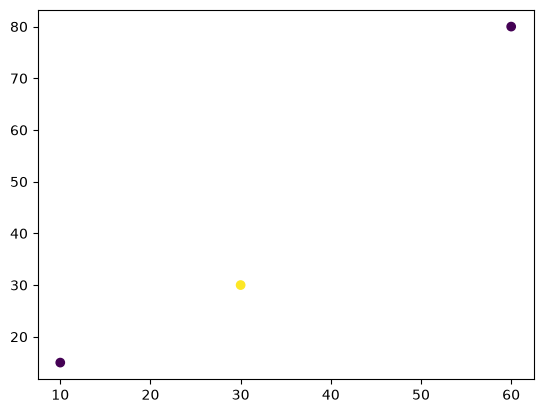

In [45]:
import matplotlib.pyplot as plt
plt.scatter( [10,30,60], [15,30,80],
             c=[0,1,0] )
plt.show()

In [41]:
x_train.columns

Index(['Alter', 'km', 'Einkommen'], dtype='str')

In [44]:
from itertools import product
import numpy as np

kmstand = np.arange(0, 500000, 10000)
einkommen = np.arange(10000, 200000, 5000)

test_kunden = []
for km,gehalt in product(kmstand, einkommen):
    kunde = {"Alter" : 40,
             "km" : km,
             "Einkommen" : gehalt}
    test_kunden.append( kunde )
test_kunden[:3]

df_hypo_kunden = pandas.DataFrame(test_kunden)
df_hypo_kunden

,Alter,km,Einkommen
0,40,0,10000
1,40,0,15000
2,40,0,20000
3,40,0,25000
4,40,0,30000
...,...,...,...
1895,40,490000,175000
1896,40,490000,180000
1897,40,490000,185000
1898,40,490000,190000


In [40]:
A = ["Belastungstest", "Hochfrequenztest"]
B = [20,30,40]

for x in product(A,B):
    print(x)

('Belastungstest', 20)
('Belastungstest', 30)
('Belastungstest', 40)
('Hochfrequenztest', 20)
('Hochfrequenztest', 30)
('Hochfrequenztest', 40)


# Quizaufgabe Modellverhalten visualisieren

1. Erzeugen Sie die Modellprädiktionen für die neuen Kunden!

2. Visualisieren Sie das Kaufverhalten über einen Scatterplot!

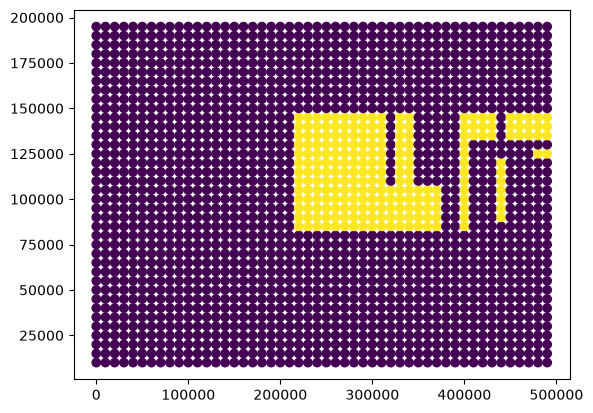

In [52]:
y_pred = model.predict( df_hypo_kunden )

plt.scatter( df_hypo_kunden["km"],
             df_hypo_kunden["Einkommen"],
             c=y_pred)
plt.show()

In [49]:
df_hypo_kunden

,Alter,km,Einkommen
0,40,0,10000
1,40,0,15000
2,40,0,20000
3,40,0,25000
4,40,0,30000
...,...,...,...
1895,40,490000,175000
1896,40,490000,180000
1897,40,490000,185000
1898,40,490000,190000


# Alles in einer finalen Codezelle

|--- Einkommen <= 80500.00
|   |--- class: 0
|--- Einkommen >  80500.00
|   |--- km <= 211684.00
|   |   |--- class: 0
|   |--- km >  211684.00
|   |   |--- Alter <= 18.50
|   |   |   |--- class: 0
|   |   |--- Alter >  18.50
|   |   |   |--- km <= 246830.00
|   |   |   |   |--- km <= 220598.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- km >  220598.50
|   |   |   |   |   |--- km <= 241536.50
|   |   |   |   |   |   |--- Einkommen <= 93500.00
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- Einkommen >  93500.00
|   |   |   |   |   |   |   |--- Einkommen <= 114500.00
|   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |--- Einkommen >  114500.00
|   |   |   |   |   |   |   |   |--- Alter <= 76.50
|   |   |   |   |   |   |   |   |   |--- km <= 231350.50
|   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |   |--- km >  231350.50
|   |   |   |   |   |   |   |   |   |   |--- Alter <= 39.50
|   |   | 

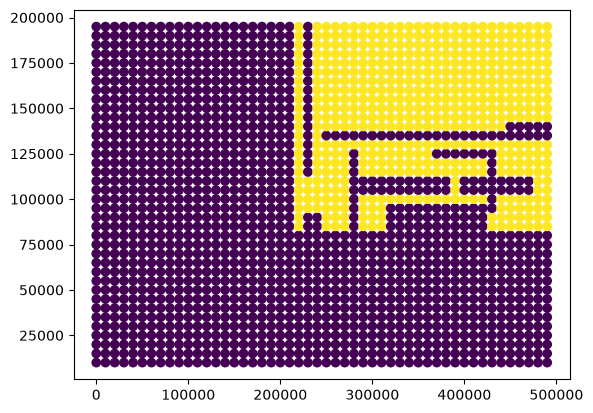

In [5]:
import numpy
import pandas

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import export_text

from itertools import product
import numpy as np
import matplotlib.pyplot as plt

# 1. Kundenfeatures simulieren
N = 1000
alter = numpy.random.randint(18,100, size=N)
km = numpy.random.randint(0,500_000, size=N)
einkommen = numpy.random.randint(15, 151, size=N) * 1000

# 2. Kaufverhalten simulieren
kaufverhalten = []
for i in range(0,N):
    if km[i] > 210_000 and einkommen[i] > 80_000:
        if numpy.random.randint(1,7) <= 2:
            kauf = 0
        else:
            kauf = 1
        
    else:
        kauf = 0
    kaufverhalten.append( kauf )

# 3. Eine Tabelle erstellen
d = {"Alter"     : alter,
     "km"        : km,
     "Einkommen" : einkommen,
     "Kauf"      : kaufverhalten}
df = pandas.DataFrame(d)

# 4. Daten fürs ML vorbereiten
# 4.1 Was ist Input x? Was ist Output y?
x = df[ ["Alter", "km", "Einkommen"] ]
y = df[ ["Kauf"] ]
# 4.2 Train-Test-Split
x_train, x_test, y_train, y_test = train_test_split(x,y,
                                          test_size=0.2)

# 5. Einen DecisionTree (DT) bauen
model = DecisionTreeClassifier()
model = model.fit(x_train, y_train)

# 6. Das Modell visualisieyren
txt = export_text(model, feature_names=x_train.columns)
print(txt[:1000])

# 7. Das Modell testen
y_pred = model.predict( x_test )
y_true = y_test["Kauf"].values
acc = accuracy_score(y_true, y_pred)
print(f"acc={acc*100}%")

# 8. Das Modellverhalten visualisieren
kmstand = np.arange(0, 500000, 10000)
einkommen = np.arange(10000, 200000, 5000)
test_kunden = []
for km,gehalt in product(kmstand, einkommen):
    kunde = {"Alter" : 40,
             "km" : km,
             "Einkommen" : gehalt}
    test_kunden.append( kunde )
df_hypo_kunden = pandas.DataFrame(test_kunden)
y_pred = model.predict( df_hypo_kunden )
plt.scatter( df_hypo_kunden["km"],
             df_hypo_kunden["Einkommen"],
             c=y_pred)
plt.show()